<a href="https://colab.research.google.com/github/JuanitaRozo/ML-NO-SUPERVISADO/blob/main/PCA_y_SVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])


[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


PCA

In [4]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

X_pca.shape

(150, 2)

In [5]:
print("Varianza explicada:")
print(pca.explained_variance_ratio_)

print(
    "Varianza explicada acumulada:",
    pca.explained_variance_ratio_.sum()
)

Varianza explicada:
[0.72962445 0.22850762]
Varianza explicada acumulada: 0.9581320720000166


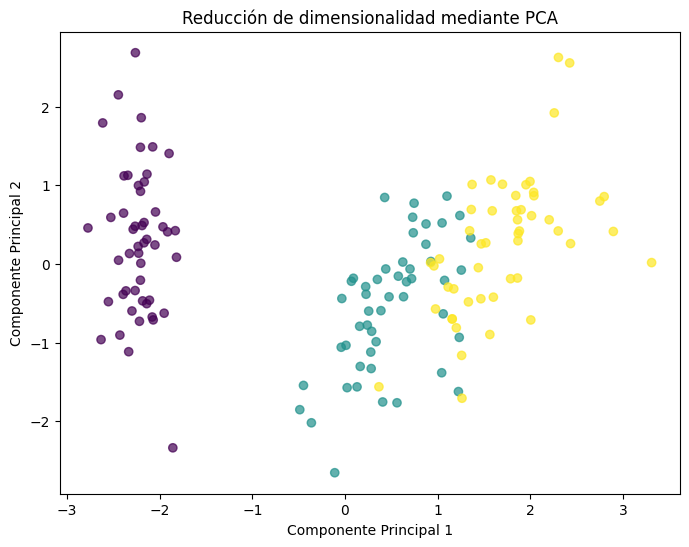

In [6]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y,
    alpha=0.7
)

plt.title("Reducción de dimensionalidad mediante PCA")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

plt.show()

SVD

In [7]:
U, S, VT = np.linalg.svd(
    X_scaled,
    full_matrices=False
)

print("Dimensiones de U:", U.shape)
print("Dimensiones de S:", S.shape)
print("Dimensiones de VT:", VT.shape)

Dimensiones de U: (150, 4)
Dimensiones de S: (4,)
Dimensiones de VT: (4, 4)


In [8]:
k = 2

X_svd = U[:, :k] @ np.diag(S[:k])

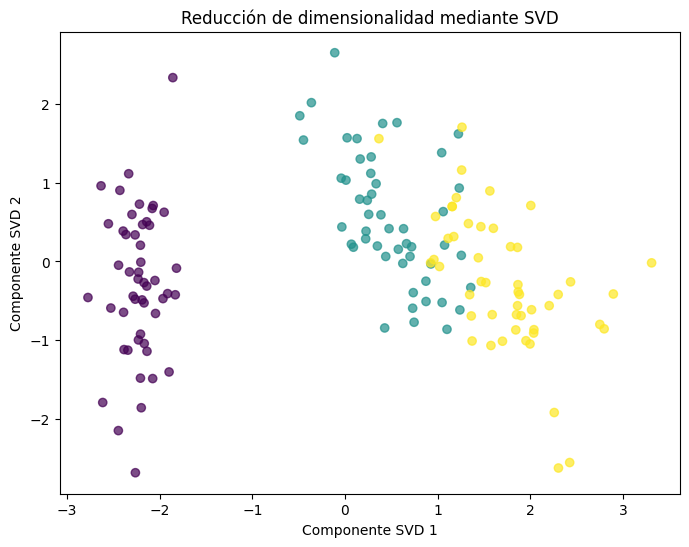

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_svd[:, 0],
    X_svd[:, 1],
    c=y,
    alpha=0.7
)

plt.title("Reducción de dimensionalidad mediante SVD")
plt.xlabel("Componente SVD 1")
plt.ylabel("Componente SVD 2")

plt.show()